# Answer or Retake: extra analysis

This notebook reads the saved score files and makes extra plots. It doesn't retrain anything or change any threshold. All numbers come from `test_scores.csv`, `ourval_scores.csv` and `flaw_probs_test.csv`.

What's inside:

1. Check: does Table 2 come out the same from the files?
2. The data: how test differs from our validation set
3. How well each score tells right answers from wrong ones
4. Risk-coverage curves with error bands
5. Why test risk ends up above the target
6. Does the question matter when the photo is blurry?
7. What the user hears when the app stays quiet
8. Medicine questions
9. Three example photos

Figures are saved in `results/figures/`. Data goes in `data/` (see `data/README.md`).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import beta
from sklearn.metrics import roc_auc_score

ROOT = Path(os.environ.get("AR_DATA", "../data"))  # see data/README.md
FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def find(name):
    for folder, _, files in sorted(os.walk(ROOT, followlinks=True)):
        if name in files and ".ipynb_checkpoints" not in folder:
            return Path(folder) / name
    raise FileNotFoundError(f"{name} not found under {ROOT.resolve()}")


test = pd.read_csv(find("test_scores.csv"))
val = pd.read_csv(find("ourval_scores.csv"))
flaw = pd.read_csv(find("flaw_probs_test.csv"))

# Optional: the VLM feature files (human flaw labels, answer types, baseline 3). Used if found.
try:
    feats = pd.read_parquet(find("features_test.parquet"))
    b3 = pd.read_parquet(find("baseline3_test.parquet")).set_index("image").loc[test["image"]].reset_index()
    assert (feats["image"] == test["image"]).all()
    HUMAN = True
except (FileNotFoundError, ImportError) as err:
    print("feature files not used:", err)
    HUMAN = False
assert (flaw["image"] == test["image"]).all(), "flaw_probs_test.csv rows must line up with test_scores.csv"

for name, df in [("test", test), ("ourval", val)]:
    print(f"{name:7s} {len(df):5d} questions | VLM correct {df.correct.mean():.3f} | answerable {df.answerable.mean():.3f}")
print(f"medicine questions in test: {test.is_medicine.sum()}")

test     4319 questions | VLM correct 0.387 | answerable 0.679
ourval   3078 questions | VLM correct 0.457 | answerable 0.728
medicine questions in test: 99


In [2]:
# Plot style: one look for every figure
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GOOD, BAD = "#0ca30c", "#d03b3b"            # right / wrong answers (always labelled)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
LIGHT_GRAY, DARK_GRAY = "#b5b3ac", "#52514e"
VAL_C, TEST_C = "#86b6ef", "#1c5cab"       # our validation / test (light and dark blue)
SHARP_C, BLUR_C = "#86b6ef", "#6250d6"     # sharp / blurry photo

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 2, "axes.axisbelow": True,
})

METHODS = {  # column suffix -> (label, colour)
    "full": ("Selector (ours)", BLUE),
    "B2": ("B2 token probability", ORANGE),
    "photo_question": ("Selector, photo + question", AQUA),
    "photo_only": ("Selector, photo only", YELLOW),
}
ALL_SCORES = ["full", "full_prompt_last", "logprob_only", "photo_question", "B2", "photo_only"]
NICE = {"full": "Selector (ours)", "full_prompt_last": "Selector, prompt-last emb.",
        "logprob_only": "Selector, log-probs only", "photo_question": "Selector, photo + question",
        "B2": "B2 token probability", "photo_only": "Selector, photo only"}
TARGETS = [1, 5, 10, 20]


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")

In [3]:
# Small helpers used throughout
rng = np.random.default_rng(0)


def rc_curve(score, correct):
    """Coverage and risk when answering the top-k questions by score, k = 1..n."""
    order = np.argsort(-np.asarray(score), kind="stable")
    err = 1 - np.asarray(correct)[order]
    k = np.arange(1, len(err) + 1)
    return k / len(err), np.cumsum(err) / k


def aurc(score, correct):
    return rc_curve(score, correct)[1].mean()


def oracle_aurc(correct):
    """Best possible AURC: every wrong answer ranked last."""
    err = np.sort(1 - np.asarray(correct))
    k = np.arange(1, len(err) + 1)
    return (np.cumsum(err) / k).mean()


def threshold_at(score, correct, target, rule="point", delta=0.10):
    """Lowest score threshold on a calibration split whose risk stays under the target.
    rule="point": observed risk <= target (the rule used for Table 2).
    rule="ucb":   one-sided Clopper-Pearson upper bound (1 - delta) <= target. This is a stricter
                  heuristic, not a formal guarantee: we still scan many thresholds and keep the largest."""
    score, correct = np.asarray(score), np.asarray(correct)
    order = np.argsort(-score, kind="stable")
    s, err = score[order], 1 - correct[order]
    k = np.arange(1, len(s) + 1)
    n_err = np.cumsum(err)
    risk = n_err / k if rule == "point" else beta.ppf(1 - delta, n_err + 1, k - n_err)
    end_of_tie = np.r_[s[1:] != s[:-1], True]
    ok = np.where((risk <= target) & end_of_tie)[0]
    return np.inf if len(ok) == 0 else s[ok.max()]


def wilson(k, n, z=1.96):
    """Wilson 95% interval (same method as the proposal's medicine CI)."""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    d = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return centre - half, centre + half


def bootstrap(stat, n, reps=1000):
    """Percentile 95% CI of stat(idx) over resampled row indices."""
    vals = np.array([stat(rng.integers(0, n, n)) for _ in range(reps)])
    return np.percentile(vals, [2.5, 97.5])

## 1. Check Table 2

We recompute Table 2 from the score files and compare it with the numbers in the proposal. We also check that picking thresholds on `ourval` gives the same answer/stay-quiet decisions as the saved `answer_*@k%` columns. B3 and B4 aren't checked here because they need other files.

In [4]:
c = test.correct.values
rows = []
for m in ALL_SCORES:
    row = {"method": NICE[m], "AURC": aurc(test[f"score_{m}"], c)}
    for t in TARGETS:
        a = test[f"answer_{m}@{t}%"].astype(bool).values
        row[f"cov@{t}%"] = a.mean()
        row[f"risk@{t}%"] = (1 - c[a]).mean() if a.any() else np.nan
    rows.append(row)
row = {"method": "B1 always answer", "AURC": 1 - c.mean()}
row.update({f"cov@{t}%": 1.0 for t in TARGETS}); row.update({f"risk@{t}%": 1 - c.mean() for t in TARGETS})
rows.append(row)
table2 = pd.DataFrame(rows).set_index("method")

# Does the threshold rule reproduce the saved decisions?
mismatches = 0
for m in ALL_SCORES:
    for t in TARGETS:
        thr = threshold_at(val[f"score_{m}"], val.correct, t / 100)
        mine = (test[f"score_{m}"].values >= thr).astype(int)
        mismatches += int((mine != test[f"answer_{m}@{t}%"].values).sum())
print(f"threshold rule vs saved answer columns: {mismatches} mismatching rows (0 = identical)")

# Numbers as printed in the proposal (Table 2 and Section 7 text)
PROPOSAL = {("B2 token probability", "cov@10%"): 0.067, ("B2 token probability", "risk@10%"): 0.134,
            ("B2 token probability", "cov@20%"): 0.261, ("B2 token probability", "risk@20%"): 0.266,
            ("B2 token probability", "AURC"): 0.373, ("Selector, photo only", "cov@10%"): 0.007,
            ("Selector, photo only", "risk@10%"): 0.156, ("Selector, photo only", "AURC"): 0.445,
            ("Selector, photo + question", "cov@10%"): 0.078, ("Selector, photo + question", "risk@10%"): 0.146,
            ("Selector, photo + question", "AURC"): 0.372, ("Selector (ours)", "cov@10%"): 0.215,
            ("Selector (ours)", "risk@10%"): 0.119, ("Selector (ours)", "AURC"): 0.317,
            ("Selector (ours)", "cov@20%"): 0.390, ("Selector (ours)", "risk@20%"): 0.237,
            ("Selector (ours)", "cov@1%"): 0.029, ("Selector (ours)", "risk@1%"): 0.024,
            ("B1 always answer", "risk@20%"): 0.613}
worst = max(abs(round(table2.loc[r, k], 3) - v) for (r, k), v in PROPOSAL.items())
print(f"{len(PROPOSAL)} proposal numbers checked, largest difference after rounding: {worst:.3f}")
table2.round(3)

threshold rule vs saved answer columns: 0 mismatching rows (0 = identical)
19 proposal numbers checked, largest difference after rounding: 0.000


,AURC,cov@1%,risk@1%,cov@5%,risk@5%,cov@10%,risk@10%,cov@20%,risk@20%
method,,,,,,,,,
Selector (ours),0.317,0.029,0.024,0.121,0.069,0.215,0.119,0.390,0.237
"Selector, prompt-last emb.",0.320,0.025,0.046,0.115,0.078,0.224,0.131,0.402,0.250
"Selector, log-probs only",0.366,0.005,0.091,0.017,0.067,0.110,0.166,0.278,0.254
"Selector, photo + question",0.372,0.003,0.000,0.019,0.060,0.078,0.146,0.225,0.225
B2 token probability,0.373,0.010,0.089,0.020,0.091,0.067,0.134,0.261,0.266
"Selector, photo only",0.445,0.000,0.000,0.000,0.000,0.007,0.156,0.057,0.256
B1 always answer,0.613,1.000,0.613,1.000,0.613,1.000,0.613,1.000,0.613


### Data checks

Quick checks on the VLM feature files (they only run if `features_test.parquet` is in the folder).

In [5]:
if HUMAN:
    import sys
    sys.path.insert(0, str(find("vqa_eval.py").parent))
    from vqa_eval import vqa_accuracy

    train_imgs = set(pd.read_parquet(find("features_train.parquet"), columns=["image"]).image)
    val_imgs, test_imgs = set(val.image), set(test.image)
    acc = np.array([vqa_accuracy(p_, list(a_)) for p_, a_ in zip(feats.vlm_answer_raw, feats.answers)])
    checks = {
        "no photo is in two splits": not (train_imgs & val_imgs or train_imgs & test_imgs or val_imgs & test_imgs),
        "test labels in test_scores.csv = feature file": bool((feats.correct.values == test.correct.values).all()),
        "VQA accuracy recomputes from the 10 human answers": bool(np.allclose(acc, feats.vqa_acc)),
        "correct = (VQA accuracy >= 0.5)": bool(((feats.vqa_acc >= 0.5).astype(int) == feats.correct).all()),
        "B2 score = sum of answer log-probs": bool(np.allclose(test.score_B2, feats.lp_sum)),
        "99 medicine questions, same in both files": bool((feats.is_medicine.values == test.is_medicine.values).all()
                                                           and test.is_medicine.sum() == 99),
    }
    b3_quiet = b3.b3_answer.str.strip().str.lower().eq("unanswerable").values
    checks["B3: coverage 0.423, risk 0.385 (proposal)"] = bool(
        round(1 - b3_quiet.mean(), 3) == 0.423 and round((1 - b3.b3_correct.values[~b3_quiet]).mean(), 3) == 0.385)
    for k, v in checks.items():
        print(("PASS  " if v else "FAIL  ") + k)

PASS  no photo is in two splits
PASS  test labels in test_scores.csv = feature file
PASS  VQA accuracy recomputes from the 10 human answers
PASS  correct = (VQA accuracy >= 0.5)
PASS  B2 score = sum of answer log-probs
PASS  99 medicine questions, same in both files
PASS  B3: coverage 0.423, risk 0.385 (proposal)


## 2. The data

Three things to know first:

- **Test is harder than our validation set.** The VLM gets fewer answers right on test, even on answerable questions. So a threshold set on validation will be a bit loose on test (Section 5).
- **Question type matters.** Colour questions are easy. Reading text (names, dates, labels) is hard, and that's what medicine questions need.
- **The VLM almost never says "unanswerable".** It said it 5 times on 1,385 unanswerable questions. Its usual replies are things like "no", "nothing", "yes" or a number.

Question types come from a simple keyword rule on the question (see the code). It's a rough grouping, not a real label.

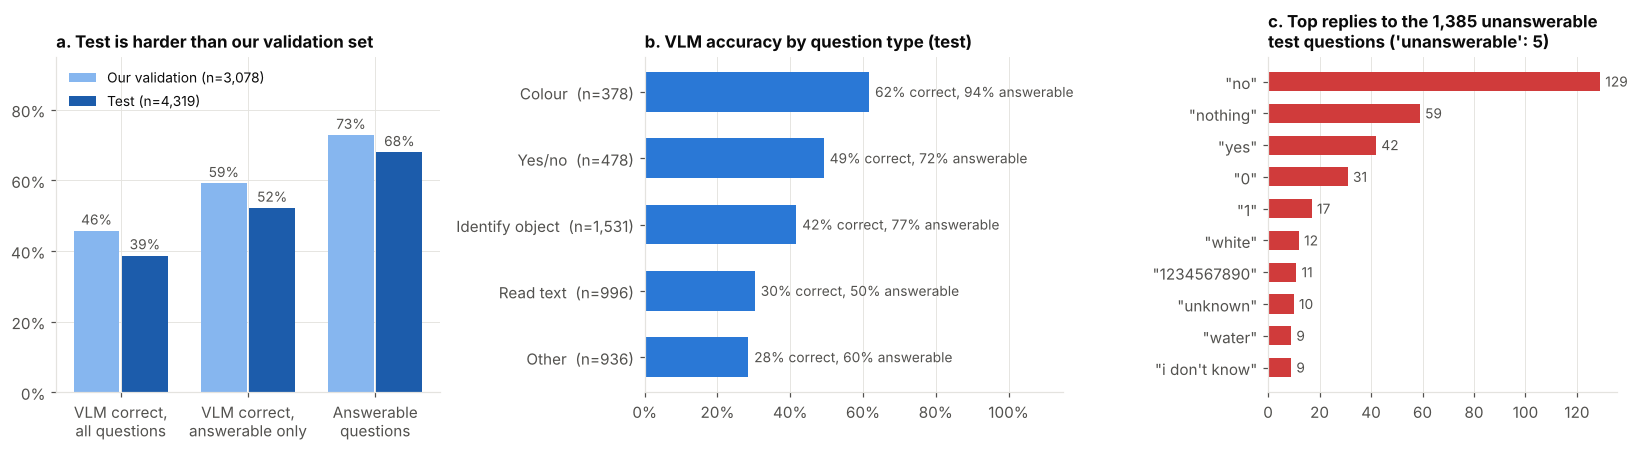

In [6]:
import re


def question_type(q):
    q = str(q).lower().strip()
    if re.search(r"colou?r", q):
        return "Colour"
    if re.search(r"\b(read|say|says|said|written|writing|text|title|name|label|brand|expir\w*|date|number|price|"
                 r"ingredient\w*|instruction\w*|dosage|dose|directions|flavou?r|amount|how much|how many|what time|"
                 r"temperature)\b", q):
        return "Read text"
    if re.match(r"^(is|are|does|do|can|will|was|has|have|did|could|should)\b", q):
        return "Yes/no"
    if re.search(r"what('s| is) (this|that|it|in)|what kind|what type|identify|what am i|what are (these|those)", q):
        return "Identify object"
    return "Other"


QTYPES = ["Colour", "Yes/no", "Identify object", "Read text", "Other"]
for df in (test, val):
    df["qtype"] = df.question.map(question_type)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1.2, 1]})

# (a) validation vs test
ax = axes[0]
stats = {
    "VLM correct,\nall questions": (val.correct.mean(), test.correct.mean()),
    "VLM correct,\nanswerable only": (val.correct[val.answerable == 1].mean(), test.correct[test.answerable == 1].mean()),
    "Answerable\nquestions": (val.answerable.mean(), test.answerable.mean()),
}
x = np.arange(len(stats))
for j, (lab, col) in enumerate([("Our validation (n=3,078)", VAL_C), ("Test (n=4,319)", TEST_C)]):
    vals_ = [v[j] for v in stats.values()]
    bars = ax.bar(x + (j - 0.5) * 0.38, vals_, 0.36, color=col, label=lab)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals_], padding=2, fontsize=9, color=INK2)
ax.set_xticks(x, stats.keys())
ax.set_ylim(0, 0.95)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(loc="upper left", fontsize=9)
ax.set_title("a. Test is harder than our validation set")

# (b) VLM accuracy by question type
ax = axes[1]
g = test.groupby("qtype").agg(acc=("correct", "mean"), n=("correct", "size"), ans=("answerable", "mean")).reindex(QTYPES)
y = np.arange(len(g))[::-1]
bars = ax.barh(y, g.acc, color=BLUE, height=0.6)
ax.set_yticks(y, [f"{q}  (n={n:,})" for q, n in zip(g.index, g.n)])
ax.bar_label(bars, labels=[f"{a:.0%} correct, {u:.0%} answerable" for a, u in zip(g.acc, g.ans)],
             padding=4, fontsize=9, color=INK2)
ax.set_xlim(0, 1.15)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("b. VLM accuracy by question type (test)")
ax.grid(axis="y", visible=False)

# (c) what the VLM says to unanswerable questions
ax = axes[2]
un = test[test.answerable == 0]
top = un.vlm_answer.value_counts().head(10)[::-1]
ax.barh(range(len(top)), top.values, color=BAD, height=0.6)
ax.set_yticks(range(len(top)), [f'"{a}"' for a in top.index])
for i, v_ in enumerate(top.values):
    ax.text(v_ + 2, i, str(v_), va="center", fontsize=9, color=INK2)
n_unk = (un.vlm_answer == "unanswerable").sum()
ax.set_title(f"c. Top replies to the {len(un):,} unanswerable\ntest questions ('unanswerable': {n_unk})")
ax.grid(axis="y", visible=False)

fig.tight_layout()
save(fig, "fig1_data_at_a_glance")
plt.show()

## 3. Does the score tell right from wrong?

AUROC: take one right answer and one wrong answer at random. How often does the score rank the right one higher? 0.5 is a coin flip, 1.0 is perfect. It doesn't depend on any threshold. Error bars are 95% bootstrap intervals (1,000 resamples).

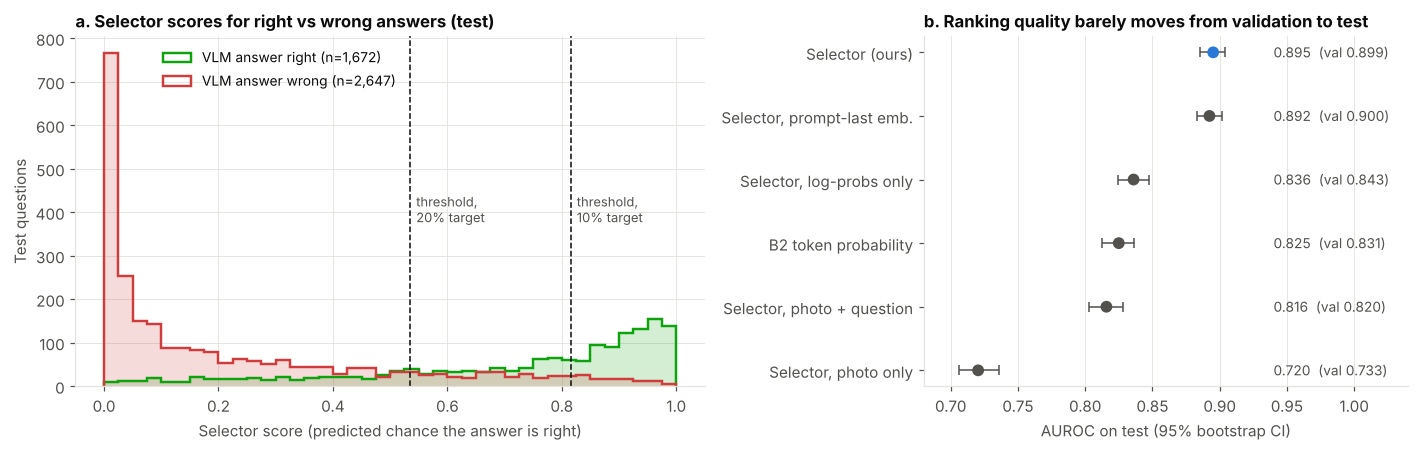

,method,test,lo,hi,val
5,"Selector, photo only",0.720,0.706,0.736,0.733
3,"Selector, photo + question",0.816,0.803,0.828,0.820
4,B2 token probability,0.825,0.812,0.836,0.831
2,"Selector, log-probs only",0.836,0.825,0.848,0.843
1,"Selector, prompt-last emb.",0.892,0.883,0.902,0.900
0,Selector (ours),0.895,0.885,0.904,0.899


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})

# (a) score histograms
ax = axes[0]
bins = np.linspace(0, 1, 41)
for lab, mask, col in [("VLM answer right", c == 1, GOOD), ("VLM answer wrong", c == 0, BAD)]:
    ax.hist(test.score_full[mask], bins=bins, color=col, alpha=0.18)
    ax.hist(test.score_full[mask], bins=bins, color=col, histtype="step", lw=1.6, label=f"{lab} (n={mask.sum():,})")
thr20 = threshold_at(val.score_full, val.correct, 0.20)
thr10 = threshold_at(val.score_full, val.correct, 0.10)
for thr, lab in [(thr20, "20% target"), (thr10, "10% target")]:
    ax.axvline(thr, color=INK, lw=1, ls="--")
    ax.text(thr + 0.01, ax.get_ylim()[1] * 0.55, f"threshold,\n{lab}", fontsize=8.5, color=INK2, va="top")
ax.set_xlabel("Selector score (predicted chance the answer is right)")
ax.set_ylabel("Test questions")
ax.legend(loc="upper left", bbox_to_anchor=(0.12, 1.0), fontsize=9)
ax.set_title("a. Selector scores for right vs wrong answers (test)")

# (b) AUROC with CIs
ax = axes[1]
res = []
for m in ALL_SCORES:
    s = test[f"score_{m}"].values
    lo, hi = bootstrap(lambda i: roc_auc_score(c[i], s[i]), len(c))
    res.append((NICE[m], roc_auc_score(c, s), lo, hi, roc_auc_score(val.correct, val[f"score_{m}"])))
res = pd.DataFrame(res, columns=["method", "test", "lo", "hi", "val"]).sort_values("test")
y = np.arange(len(res))
cols = [BLUE if m == "Selector (ours)" else DARK_GRAY for m in res.method]
ax.errorbar(res.test, y, xerr=[res.test - res.lo, res.hi - res.test], fmt="none", ecolor=INK2, capsize=3, lw=1)
ax.scatter(res.test, y, color=cols, s=45, zorder=3)
for yi, (t_, v_) in enumerate(zip(res.test, res.val)):
    ax.text(0.94, yi, f"{t_:.3f}  (val {v_:.3f})", va="center", fontsize=9, color=INK2)
ax.set_yticks(y, res.method)
ax.set_xlim(0.68, 1.04)
ax.axvline(0.5, color=GRID)
ax.set_xlabel("AUROC on test (95% bootstrap CI)")
ax.set_title("b. Ranking quality barely moves from validation to test")
ax.grid(axis="y", visible=False)

fig.tight_layout()
save(fig, "fig2_score_separation")
plt.show()
res.round(3)

## 4. Risk-coverage curves with error bands

Same curves as Figure 3 in the proposal, plus three things:

- **Shaded bands:** the 95% bootstrap range for ours and B2. This is a visual guide only. The proper test is the paired bootstrap in the proposal (AURC difference -0.056, 95% CI -0.065 to -0.047).
- **Oracle line:** the best any selector could do with this VLM (all wrong answers ranked last).
- **Excess AURC (E-AURC):** AURC minus the oracle's AURC. Plain AURC gets worse when the VLM itself is worse. E-AURC takes most of that out, so it's fairer when comparing validation with test.

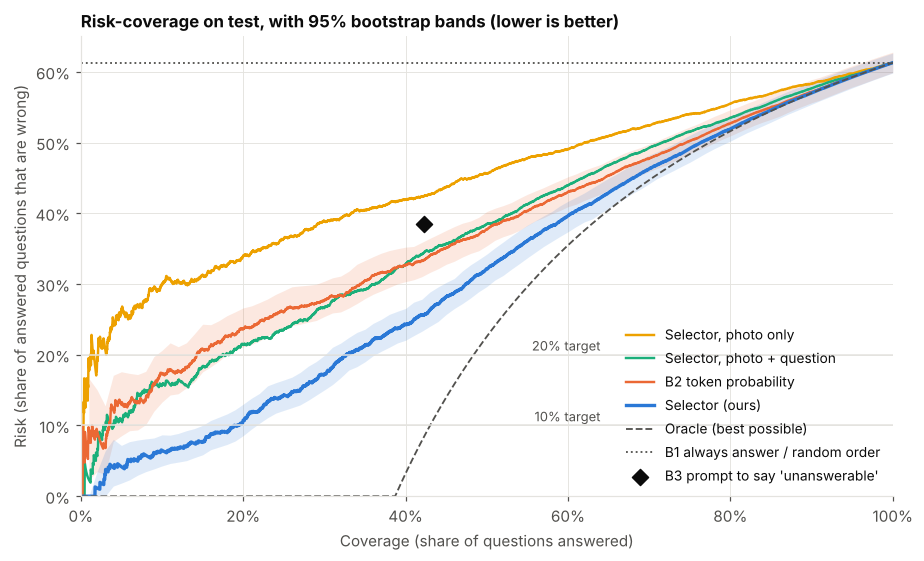

oracle AURC: test 0.246, val 0.185


,AURC test,95% CI,E-AURC test,E-AURC val
method,,,,
Selector (ours),0.317,0.301 to 0.333,0.072,0.062
"Selector, prompt-last emb.",0.320,0.305 to 0.337,0.074,0.062
"Selector, log-probs only",0.366,0.349 to 0.386,0.120,0.104
"Selector, photo + question",0.372,0.354 to 0.391,0.127,0.115
B2 token probability,0.373,0.354 to 0.392,0.128,0.112
"Selector, photo only",0.445,0.426 to 0.466,0.199,0.181


In [8]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
grid = np.linspace(0.01, 1, 100)


def curve_on_grid(score, correct):
    cov, risk = rc_curve(score, correct)
    return np.interp(grid, cov, risk)


for m in ["photo_only", "photo_question", "B2", "full"]:
    lab, col = METHODS[m]
    s = test[f"score_{m}"].values
    cov, risk = rc_curve(s, c)
    ax.plot(cov, risk, color=col, label=lab, lw=2.2 if m == "full" else 1.6)
    if m in ("full", "B2"):
        boots = np.array([curve_on_grid(s[i], c[i]) for i in (rng.integers(0, len(c), len(c)) for _ in range(300))])
        ax.fill_between(grid, *np.percentile(boots, [2.5, 97.5], axis=0), color=col, alpha=0.15, lw=0)

cov_o, risk_o = rc_curve(c, c)  # ranking by the true label = oracle
ax.plot(cov_o, risk_o, color=INK2, ls="--", lw=1.2, label="Oracle (best possible)")
ax.axhline(1 - c.mean(), color=INK2, ls=":", lw=1.2, label="B1 always answer / random order")
if HUMAN:
    q3 = b3.b3_answer.str.strip().str.lower().eq("unanswerable").values
    ax.scatter(1 - q3.mean(), (1 - b3.b3_correct.values[~q3]).mean(), marker="D", s=55, color=INK, zorder=5,
               label="B3 prompt to say 'unanswerable'")
for t in (0.10, 0.20):
    ax.axhline(t, color=GRID, lw=1)
    ax.text(0.64, t + 0.006, f"{t:.0%} target", fontsize=8.5, color=INK2, ha="right")

ax.set_xlim(0, 1); ax.set_ylim(0, 0.65)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Coverage (share of questions answered)")
ax.set_ylabel("Risk (share of answered questions that are wrong)")
ax.set_title("Risk-coverage on test, with 95% bootstrap bands (lower is better)")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
save(fig, "fig3_risk_coverage_bands")
plt.show()

rows = []
for m in ALL_SCORES:
    s = test[f"score_{m}"].values
    lo, hi = bootstrap(lambda i: aurc(s[i], c[i]), len(c), reps=500)
    rows.append({"method": NICE[m], "AURC test": aurc(s, c), "95% CI": f"{lo:.3f} to {hi:.3f}",
                 "E-AURC test": aurc(s, c) - oracle_aurc(c),
                 "E-AURC val": aurc(val[f"score_{m}"], val.correct) - oracle_aurc(val.correct)})
eaurc = pd.DataFrame(rows).set_index("method").sort_values("AURC test")
print(f"oracle AURC: test {oracle_aurc(c):.3f}, val {oracle_aurc(val.correct):.3f}")
eaurc.round(3)

## 5. Why test risk ends up above the target

In the proposal, test risk is 1.4 to 3.7 points above each target. There are three possible reasons:

1. **Luck.** The threshold is picked on 3,078 questions, so it moves a bit by chance.
2. **The selector ranks worse on test.** Section 3 says no: AUROC is 0.899 on validation and 0.895 on test.
3. **Test is harder.** At the same score, slightly more answers are wrong.

The plots check reasons 1 and 3:

- **a.** Calibration plot. On validation, a score of 0.7 means about 70% of answers are right. On test, mid and high scores come out a few points lower, which points to reason 3.
- **b.** Test risk across many targets. We also try a stricter rule: pick the threshold so a 90% upper bound on validation risk stays under the target. It's a rough fix with no guarantee, because it protects against luck, not against a harder test set.
- **c.** How much overshoot does luck alone give? We split our validation set in half 300 times, set the threshold on one half and measure risk on the other. There's no shift here, so the spread is pure luck. Then we compare it with the real test overshoot.

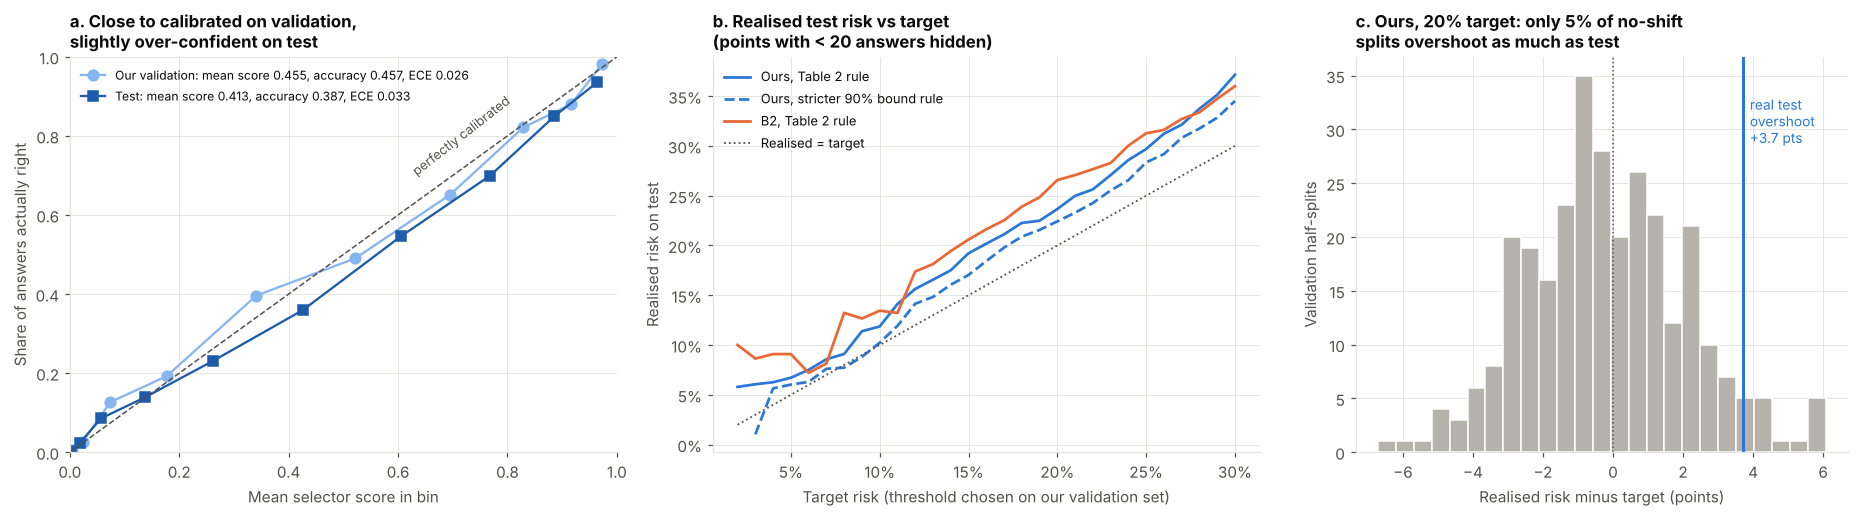

,method,target,test risk,95% CI (threshold re-picked),overshoot (points),share of no-shift splits overshooting this much,stricter rule: coverage,stricter rule: test risk
0,Selector (ours),10%,0.119,0.087 to 0.161,1.866,0.177,0.197,0.102
1,Selector (ours),20%,0.237,0.211 to 0.269,3.708,0.047,0.368,0.224
2,B2 token probability,10%,0.134,0.083 to 0.198,3.448,0.197,0.026,0.072
3,B2 token probability,20%,0.266,0.226 to 0.295,6.572,0.007,0.212,0.240


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1, 0.9]})

# (a) reliability diagram, 10 equal-count bins
ax = axes[0]
for name, df, col, mk in [("Our validation", val, VAL_C, "o"), ("Test", test, TEST_C, "s")]:
    q = pd.qcut(df.score_full, 10, duplicates="drop")
    g = df.groupby(q, observed=True).agg(p=("score_full", "mean"), acc=("correct", "mean"))
    ece = (df.groupby(q, observed=True).size() / len(df) * (g.p - g.acc).abs()).sum()
    ax.plot(g.p, g.acc, marker=mk, ms=7, color=col, lw=1.5,
            label=f"{name}: mean score {df.score_full.mean():.3f}, accuracy {df.correct.mean():.3f}, ECE {ece:.3f}")
ax.plot([0, 1], [0, 1], color=INK2, ls="--", lw=1)
ax.text(0.62, 0.70, "perfectly calibrated", rotation=38, fontsize=8.5, color=INK2)
ax.set_xlabel("Mean selector score in bin")
ax.set_ylabel("Share of answers actually right")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(loc="upper left", fontsize=8)
ax.set_title("a. Close to calibrated on validation,\nslightly over-confident on test")

# (b) target vs realised test risk
ax = axes[1]
targets = np.arange(0.02, 0.305, 0.01)
for m, rule, ls, lab in [("full", "point", "-", "Ours, Table 2 rule"), ("full", "ucb", "--", "Ours, stricter 90% bound rule"),
                         ("B2", "point", "-", "B2, Table 2 rule")]:
    realised = []
    for t in targets:
        thr = threshold_at(val[f"score_{m}"], val.correct, t, rule=rule)
        a = test[f"score_{m}"].values >= thr
        realised.append((1 - c[a]).mean() if a.sum() >= 20 else np.nan)
    ax.plot(targets, realised, ls=ls, color=METHODS[m][1], label=lab, lw=1.8)
ax.plot(targets, targets, color=INK2, ls=":", lw=1.2, label="Realised = target")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_xlabel("Target risk (threshold chosen on our validation set)")
ax.set_ylabel("Realised risk on test")
ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("b. Realised test risk vs target\n(points with < 20 answers hidden)")


def no_shift_overshoot(m, target, reps=300):
    """Pick the threshold on one random half of ourval, measure risk on the other half."""
    s_, c_ = val[f"score_{m}"].values, val.correct.values
    out = []
    for _ in range(reps):
        p = rng.permutation(len(s_))
        a_, b_ = p[: len(p) // 2], p[len(p) // 2:]
        ans = s_[b_] >= threshold_at(s_[a_], c_[a_], target)
        if ans.any():
            out.append((1 - c_[b_][ans]).mean() - target)
    return np.array(out)


def joint_bootstrap_risk(m, target, reps=300):
    """Resample ourval and test together, re-pick the threshold each time: CI of realised test risk."""
    sv, cv, st = val[f"score_{m}"].values, val.correct.values, test[f"score_{m}"].values
    out = []
    for _ in range(reps):
        i, j = rng.integers(0, len(sv), len(sv)), rng.integers(0, len(st), len(st))
        ans = st[j] >= threshold_at(sv[i], cv[i], target)
        if ans.any():
            out.append((1 - c[j][ans]).mean())
    return np.percentile(out, [2.5, 97.5])


rows, sims = [], {}
for m in ["full", "B2"]:
    for t in [0.10, 0.20]:
        a = test[f"answer_{m}@{int(t * 100)}%"].astype(bool).values
        obs = (1 - c[a]).mean() - t
        ns = no_shift_overshoot(m, t)
        sims[(m, t)] = (ns, obs)
        lo, hi = joint_bootstrap_risk(m, t)
        thr_u = threshold_at(val[f"score_{m}"], val.correct, t, rule="ucb")
        au = test[f"score_{m}"].values >= thr_u
        rows.append({"method": NICE[m], "target": f"{t:.0%}", "test risk": (1 - c[a]).mean(),
                     "95% CI (threshold re-picked)": f"{lo:.3f} to {hi:.3f}",
                     "overshoot (points)": 100 * obs,
                     "share of no-shift splits overshooting this much": (ns >= obs).mean(),
                     "stricter rule: coverage": au.mean(),
                     "stricter rule: test risk": (1 - c[au]).mean() if au.any() else np.nan})

# (c) no-shift overshoot distribution, ours at the 20% target
ax = axes[2]
ns, obs = sims[("full", 0.20)]
ax.hist(100 * ns, bins=25, color=LIGHT_GRAY, edgecolor="white")
ax.axvline(100 * obs, color=BLUE, lw=2)
ax.axvline(0, color=INK2, ls=":", lw=1)
ax.text(100 * obs + 0.2, ax.get_ylim()[1] * 0.9, f"real test\novershoot\n{100 * obs:+.1f} pts", color=BLUE, fontsize=9, va="top")
ax.set_xlabel("Realised risk minus target (points)")
ax.set_ylabel("Validation half-splits")
ax.set_title(f"c. Ours, 20% target: only {(ns >= obs).mean():.0%} of no-shift\nsplits overshoot as much as test")

fig.tight_layout()
save(fig, "fig4_shift_and_threshold_rules")
plt.show()
pd.DataFrame(rows).round(3)

## 6. Does the question matter when the photo is blurry?

The proposal's example: a blurry photo may still answer "what colour is it?" but not "what's the expiry date?". Here we check it on the test set. A photo counts as blurry if most of its 5 annotators said blur (1,379 photos, same as the proposal). Without the feature file, the notebook falls back to the flaw head's guess (blur score 0.34 or more). Error bars are 95% Wilson intervals.

Limits: question types come from keywords, and the share of answerable questions also differs between groups.

blurry test photos: 1,379 (human label, 3+ of 5 votes)


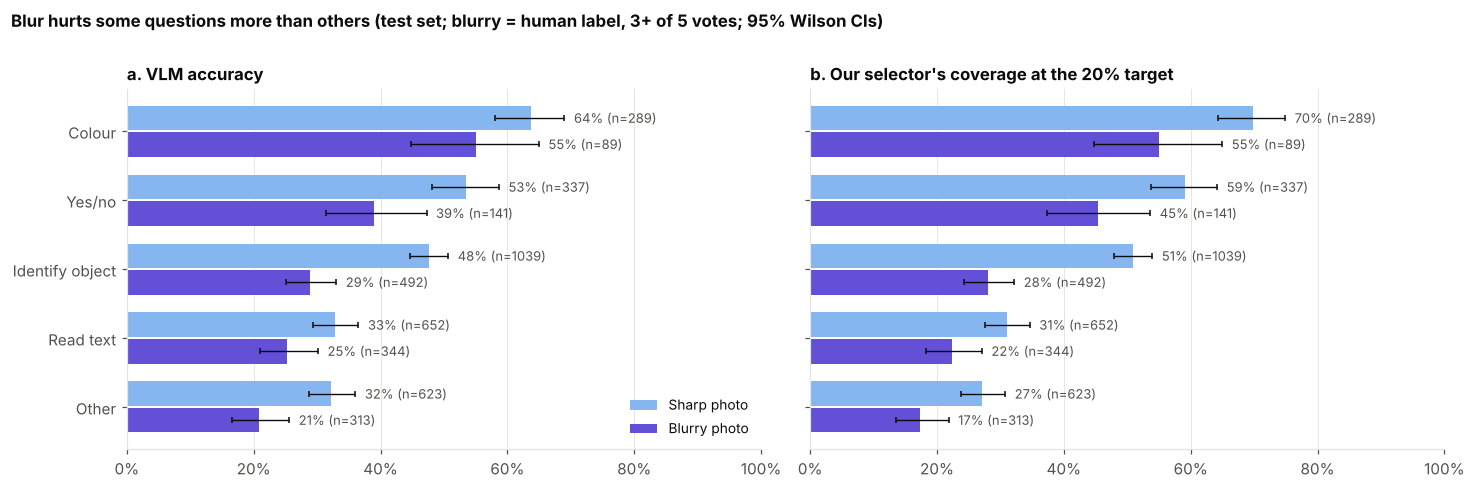

,accuracy drop when blurry (points),"answerable, sharp","answerable, blurry"
qtype,,,
Colour,8.61,0.97,0.88
Yes/no,14.41,0.79,0.55
Identify object,18.78,0.86,0.58
Read text,7.53,0.58,0.33
Other,11.50,0.67,0.46


In [10]:
# Blurry = majority of the 5 annotators said blur (human label) when the feature file is here,
# otherwise the flaw head's guess at its 0.34 cut-off.
test["blurry"] = (feats["flaw_BLR"].astype(float).values >= 3) if HUMAN else (flaw["p_BLR"].values >= 0.34)
BLUR_SRC = "human label, 3+ of 5 votes" if HUMAN else "flaw head p(blur) >= 0.34"
print(f"blurry test photos: {test.blurry.sum():,} ({BLUR_SRC})")
test["ans20"] = test["answer_full@20%"].astype(bool)
g = test.groupby(["qtype", "blurry"]).agg(k_acc=("correct", "sum"), k_cov=("ans20", "sum"), n=("correct", "size"),
                                          answerable=("answerable", "mean"))
g["acc"], g["cov"] = g.k_acc / g.n, g.k_cov / g.n

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4), sharey=True)
y = np.arange(len(QTYPES))[::-1]
for ax, col_, kcol, title in [(axes[0], "acc", "k_acc", "a. VLM accuracy"),
                              (axes[1], "cov", "k_cov", "b. Our selector's coverage at the 20% target")]:
    for j, (blur, colr, lab) in enumerate([(False, SHARP_C, "Sharp photo"), (True, BLUR_C, "Blurry photo")]):
        sub = g.xs(blur, level="blurry").reindex(QTYPES)
        ci = np.array([wilson(k, n) for k, n in zip(sub[kcol], sub.n)])
        yy = y + (0.5 - j) * 0.38
        ax.barh(yy, sub[col_], 0.36, color=colr, label=lab)
        ax.errorbar(sub[col_], yy, xerr=[sub[col_] - ci[:, 0], ci[:, 1] - sub[col_]], fmt="none", ecolor=INK, lw=0.9, capsize=2)
        for yi, v_, n_, hi_ in zip(yy, sub[col_], sub.n, ci[:, 1]):
            ax.text(hi_ + 0.015, yi, f"{v_:.0%} (n={n_})", va="center", fontsize=8.5, color=INK2)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, QTYPES)
axes[0].legend(loc="lower right", fontsize=9)
fig.suptitle(f"Blur hurts some questions more than others (test set; blurry = {BLUR_SRC}; 95% Wilson CIs)",
             x=0.01, ha="left", fontsize=11, fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "fig5_question_type_x_blur")
plt.show()

summary = pd.DataFrame({
    "accuracy drop when blurry (points)": 100 * (g.xs(False, level="blurry").acc - g.xs(True, level="blurry").acc),
    "answerable, sharp": g.xs(False, level="blurry").answerable,
    "answerable, blurry": g.xs(True, level="blurry").answerable,
}).reindex(QTYPES)
summary.round(2)

## 7. What the user hears when the app stays quiet

When our selector holds back an answer, the flaw head picks the tip: the most likely flaw above its 0.34 cut-off. If no flaw passes the cut-off, there's no tip. Below is what users would hear at the 20% target, and what happens per 100 questions.

Watch the "no tip" group. The flaw head thinks the photo is fine, but the selector still doesn't trust the answer, so the user just gets silence. That's the bare "I don't know" the proposal wants to avoid.

These counts use the flaw head's guesses. With human labels, 34% of flawed photos have 2 or more flaws (proposal); the flaw head's guesses give 39%.

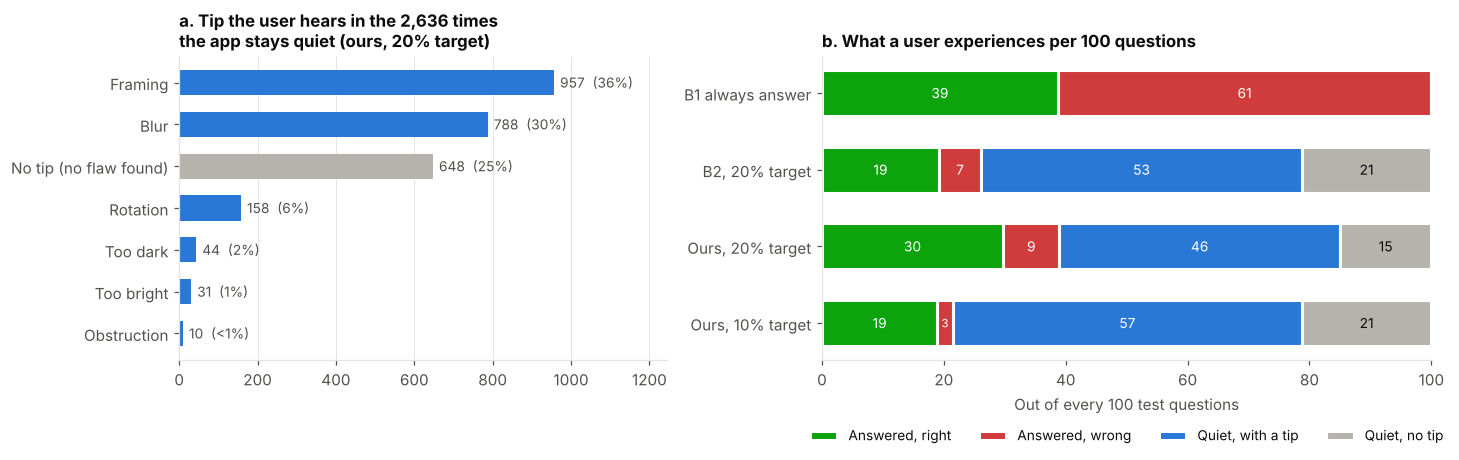

abstentions with no tip: 648 (25% of abstentions); 70% of these questions are answerable by humans
flawed photos (by the flaw head) with 2+ flaws above the cut-off: 39%
correct answers withheld at the 20% target: 23%

tips that name a flaw most annotators also saw: 72% of 1,988 spoken tips
   Blur         tip: right 83% (n=788)
   Framing      tip: right 65% (n=957)
   Rotation     tip: right 66% (n=158)
   Too dark     tip: right 82% (n=44)
   Too bright   tip: right 55% (n=31)

'no tip' cases (648): humans saw a flaw in 33%, and called the photo unrecognisable in 2%


In [11]:
FLAWS = {"BLR": "Blur", "FRM": "Framing", "ROT": "Rotation", "DRK": "Too dark", "BRT": "Too bright", "OBS": "Obstruction"}
CUTOFF = 0.34
P = flaw[[f"p_{k}" for k in FLAWS]].values
any_flaw = (P >= CUTOFF).any(axis=1)
tip = np.where(any_flaw, np.array(list(FLAWS.values()))[P.argmax(axis=1)], "No tip (no flaw found)")
n_flaws = (P >= CUTOFF).sum(axis=1)
test["tip"] = tip

abst = ~test.ans20
dist = test.loc[abst, "tip"].value_counts()
no_tip = abst & ~any_flaw

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
order = dist.sort_values().index
cols = [LIGHT_GRAY if k.startswith("No tip") else BLUE for k in order]
ax.barh(range(len(order)), dist[order].values, color=cols, height=0.6)
ax.set_yticks(range(len(order)), order)
for i, k in enumerate(order):
    share = dist[k] / abst.sum()
    ax.text(dist[k] + 15, i, f"{dist[k]:,}  ({share:.0%})" if share >= 0.005 else f"{dist[k]:,}  (<1%)",
            va="center", fontsize=9, color=INK2)
ax.set_xlim(0, dist.max() * 1.3)
ax.set_title(f"a. Tip the user hears in the {abst.sum():,} times\nthe app stays quiet (ours, 20% target)")
ax.grid(axis="y", visible=False)

# (b) outcome per 100 questions
ax = axes[1]


def outcome(answered):
    answered = np.asarray(answered, bool)
    return {"Answered, right": (answered & (c == 1)).mean(), "Answered, wrong": (answered & (c == 0)).mean(),
            "Quiet, with a tip": (~answered & any_flaw).mean(), "Quiet, no tip": (~answered & ~any_flaw).mean()}


rows = {"B1 always answer": outcome(np.ones(len(c))), "B2, 20% target": outcome(test["answer_B2@20%"]),
        "Ours, 20% target": outcome(test.ans20), "Ours, 10% target": outcome(test["answer_full@10%"])}
seg_cols = {"Answered, right": GOOD, "Answered, wrong": BAD, "Quiet, with a tip": BLUE, "Quiet, no tip": LIGHT_GRAY}
y = np.arange(len(rows))[::-1]
left = np.zeros(len(rows))
for seg, col in seg_cols.items():
    w = np.array([100 * r[seg] for r in rows.values()])
    ax.barh(y, w, left=left, color=col, height=0.6, label=seg, edgecolor="white", linewidth=2)
    for yi, (l, wi) in enumerate(zip(left, w)):
        if wi >= 2:
            ax.text(l + wi / 2, y[yi], f"{wi:.0f}", ha="center", va="center", fontsize=9 if wi >= 6 else 7.5,
                    color="white" if col != LIGHT_GRAY else INK)
    left += w
ax.set_yticks(y, rows.keys())
ax.set_xlim(0, 100)
ax.set_xlabel("Out of every 100 test questions")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=9)
ax.set_title("b. What a user experiences per 100 questions")
ax.grid(False)

fig.tight_layout()
save(fig, "fig6_what_the_user_hears")
plt.show()

print(f"abstentions with no tip: {no_tip.sum():,} ({no_tip.sum() / abst.sum():.0%} of abstentions); "
      f"{test.answerable[no_tip].mean():.0%} of these questions are answerable by humans")
print(f"flawed photos (by the flaw head) with 2+ flaws above the cut-off: {(n_flaws[any_flaw] >= 2).mean():.0%}")
print(f"correct answers withheld at the 20% target: {(abst & (c == 1)).sum() / (c == 1).sum():.0%}")

if HUMAN:
    # Is the spoken tip about a real flaw? Human label = 3+ of 5 annotators.
    H = np.stack([feats[f"flaw_{k}"].astype(float).values >= 3 for k in FLAWS], axis=1)
    tip_idx = P.argmax(axis=1)
    tipped = abst & any_flaw
    tip_right = H[np.arange(len(H)), tip_idx]
    print(f"\ntips that name a flaw most annotators also saw: {tip_right[tipped].mean():.0%} "
          f"of {tipped.sum():,} spoken tips")
    for k_i, k in enumerate(FLAWS.values()):
        sel = tipped & (tip_idx == k_i)
        if sel.sum() >= 20:
            print(f"   {k:12s} tip: right {tip_right[sel].mean():.0%} (n={sel.sum()})")
    unrec = feats["flaw_unrecognizable"].astype(float).values >= 3
    print(f"\n'no tip' cases ({no_tip.sum()}): humans saw a flaw in {H[no_tip].any(axis=1).mean():.0%}, "
          f"and called the photo unrecognisable in {unrec[no_tip].mean():.0%}")

## 8. Medicine questions (n = 99)

This is a small set, so every number has a 95% Wilson interval (the same method as the proposal). The two methods answer different numbers of questions, so read the risk and the count together. Overlapping intervals mean the difference isn't proven yet; they're not a formal test.

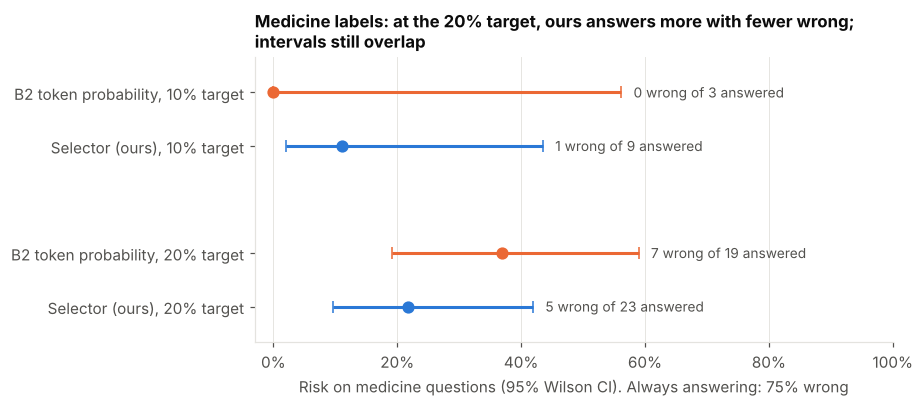

tips heard on medicine questions when ours abstains (20% target):
tip
Blur                      32
Framing                   22
No tip (no flaw found)    20
Too dark                   1
Rotation                   1


,method,target,answered,wrong,risk,lo,hi
0,B2 token probability,10,3,0,0.000,0.000,0.562
1,B2 token probability,20,19,7,0.368,0.191,0.590
2,Selector (ours),10,9,1,0.111,0.020,0.435
3,Selector (ours),20,23,5,0.217,0.097,0.419


In [12]:
med = test[test.is_medicine].copy()
cm = med.correct.values
rows = []
for m in ["B2", "full"]:
    for t in [10, 20]:
        a = med[f"answer_{m}@{t}%"].astype(bool).values
        k, n = int((1 - cm[a]).sum()), int(a.sum())
        lo, hi = wilson(k, n)
        rows.append({"method": NICE[m], "target": t, "answered": n, "wrong": k,
                     "risk": k / n if n else np.nan, "lo": lo, "hi": hi})
mr = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ypos = {("B2 token probability", 10): 3, ("Selector (ours)", 10): 2.4, ("B2 token probability", 20): 1.2, ("Selector (ours)", 20): 0.6}
for _, r in mr.iterrows():
    yy = ypos[(r.method, r.target)]
    col = BLUE if r.method == "Selector (ours)" else ORANGE
    if r.answered:
        ax.errorbar(r.risk, yy, xerr=[[r.risk - r.lo], [r.hi - r.risk]], fmt="o", color=col, ecolor=col, capsize=4, ms=7)
        ax.text(r.hi + 0.02, yy, f"{r.wrong} wrong of {r.answered} answered", va="center", fontsize=9, color=INK2)
ax.set_yticks(list(ypos.values()), [f"{m}, {t}% target" for m, t in ypos])
ax.set_xlim(-0.03, 1.0); ax.set_ylim(0.2, 3.4)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel(f"Risk on medicine questions (95% Wilson CI). Always answering: {1 - cm.mean():.0%} wrong")
ax.set_title("Medicine labels: at the 20% target, ours answers more with fewer wrong;\nintervals still overlap")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "fig7_medicine_ci")
plt.show()

print("tips heard on medicine questions when ours abstains (20% target):")
print(med.loc[~med.ans20, "tip"].value_counts().to_string())
mr.round(3)

## 9. Three example photos

These are the three test photos we use to check the demo setup. Each one shows the question, the VLM's answer, whether the crowd agreed, our selector's score, and what the app would do at the 20% target.

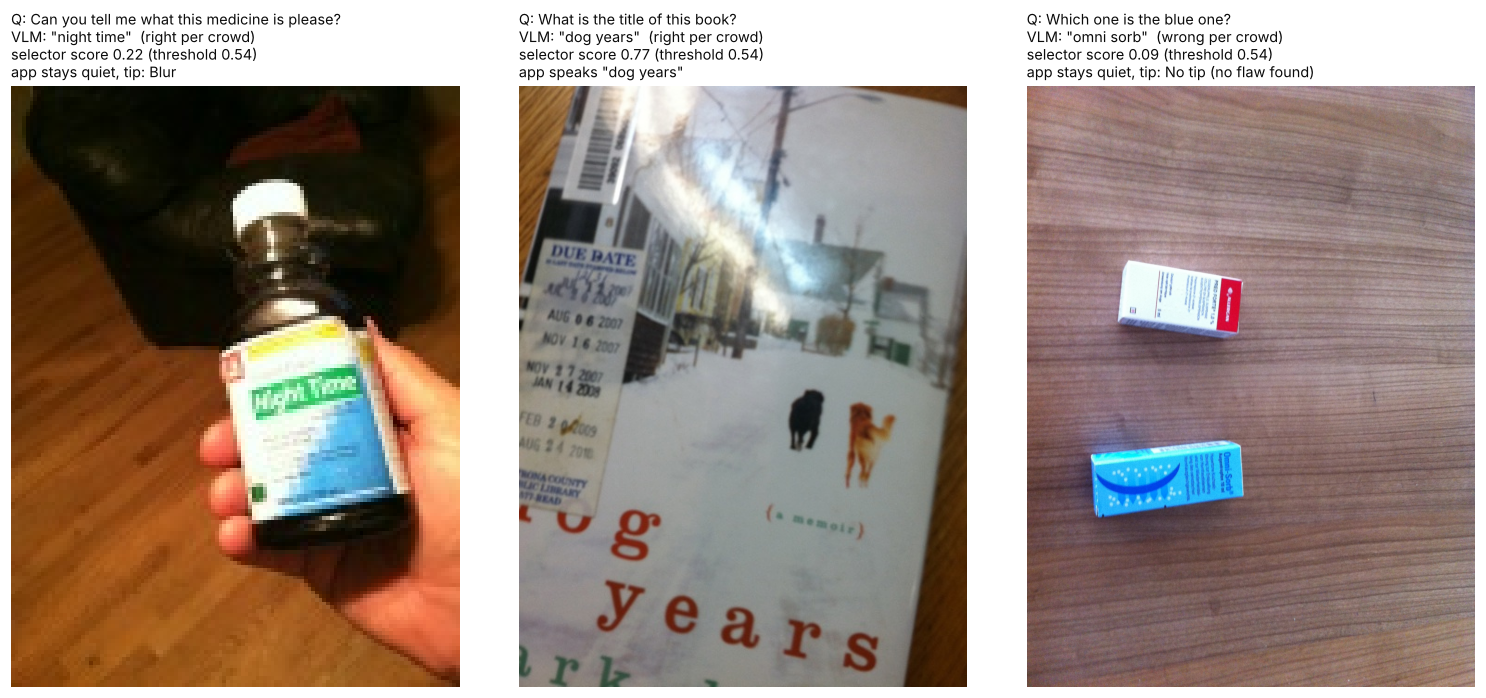

In [13]:
from PIL import Image

ids = ["VizWiz_val_00000001.jpg", "VizWiz_val_00000002.jpg", "VizWiz_val_00000003.jpg"]
fig, axes = plt.subplots(1, 3, figsize=(14, 6.2))
for ax, img_id in zip(axes, ids):
    r = test.set_index("image").loc[img_id]
    try:
        ax.imshow(Image.open(find(img_id)))  # loaded as stored, no EXIF rotation, like the VLM
    except FileNotFoundError:
        ax.text(0.5, 0.5, "photo not found", ha="center", va="center", transform=ax.transAxes)
    ax.set_axis_off()
    decision = f'speaks "{r.vlm_answer}"' if r.ans20 else f"stays quiet, tip: {r.tip}"
    ax.set_title(f'Q: {r.question.strip()}\nVLM: "{r.vlm_answer}"  ({"right" if r.correct else "wrong"} per crowd)\n'
                 f"selector score {r.score_full:.2f} (threshold {thr20:.2f})\napp {decision}",
                 fontsize=9.5, fontweight="normal", loc="left")
fig.tight_layout()
save(fig, "fig8_examples")
plt.show()

## Takeaways

- **Table 2 checks out.** Every row we could recompute from these files matches the proposal.
- **The selector ranks just as well on test** (AUROC 0.899 on validation, 0.895 on test).
- **Missing the 10% target is mostly luck.** Test is 1.9 points over, and 18% of the no-shift splits miss by that much or more.
- **Missing the 20% target is more than luck.** Test is 3.7 points over, which only 5% of splits do, so the test set is also a bit harder. The stricter rule helps a little but isn't a fix. A real app would need to re-check the threshold on its own users' photos.
- **Ours beats B2 on both splits.** Excess AURC is 0.072 vs 0.128 on test, and 0.062 vs 0.112 on validation.
- **The question matters on blurry photos.** With the human blur labels, colour questions drop 9 points (64% to 55% right) and the selector still answers 55% of them. "What is this" questions drop 19 points (48% to 29%) and it answers only 28%.
- **Tips are mostly right.** 72% of spoken tips name a flaw most annotators also saw (blur tips 83%, framing tips 65%).
- **A quarter of the quiet moments have no tip** (648 of 2,636). In a third of those, humans did see a flaw the flaw head missed, and 70% of the questions could be answered by a person. They need a neutral fallback message, for example *"I'm not sure about this one. Try another angle, or ask someone to check."*
- **Medicine:** at the 20% target, ours answers 23 and gets 5 wrong (22%, CI 10 to 42%). B2 answers 19 and gets 7 wrong (37%, CI 19 to 59%). Ours answers more and makes fewer mistakes, but with only 99 questions the intervals overlap.